# Módulo 2 (continuação) — Comparação da semana completa: NFStream+rotulagem vs. CICIDS2017 original
**Objetivo:** estender a comparação de quinta-feira para todos os dias com ataque (terça a sexta), mostrando **valor absoluto e percentual** lado a lado, por dia e agregado.
**Autor:** Marcel Teixeira Chiarelo
**Data:** outubro/2026

**Pipeline (como esta notebook se encaixa):**
1. `extrair_nfstream_pcaps.py` roda o NFStream nos PCAPs e gera `captura_nfstream_<dia>.csv` (um por dia).
2. Esta notebook rotula cada dia com `label_dataframe` (IP + horário em `America/Moncton`, definido em `rotulagem_cicids2017.py`) e compara com os CSVs oficiais da CICIDS2017.

Segunda-feira fica de fora de propósito: só tem tráfego benigno e a referência agregada que tenho é de terça a sexta.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import pandas as pd

from rotulagem_cicids2017 import (
    label_dataframe,
    ler_csv_original_cicids2017,
    normalizar_label,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1. Configuração

- `DIAS`: nome do dia → (CSV do NFStream gerado na extração, prefixo dos CSVs oficiais do dia).
- Se algum CSV do NFStream não existir ainda, o dia é pulado e a notebook segue com os demais.

In [2]:
DIAS = {
    "terca":  ("captura_nfstream_tuesday.csv",   "Tuesday"),
    "quarta": ("captura_nfstream_wednesday.csv", "Wednesday"),
    "quinta": ("captura_nfstream_thursday.csv",  "Thursday"),
    "sexta":  ("captura_nfstream_friday.csv",    "Friday"),
}

# So preciso destas tres colunas do NFStream para rotular (e os CSVs sao grandes).
COLUNAS_NFSTREAM = ["src_ip", "dst_ip", "bidirectional_first_seen_ms"]

PASTA_ORIGINAIS = "dados"

## 2. Nossa base: carregar e rotular cada dia

In [3]:
dfs_nosso = []
for dia, (csv_nfstream, _) in DIAS.items():
    if not os.path.exists(csv_nfstream):
        print(f"[pulando] {dia}: {csv_nfstream} nao encontrado")
        continue
    d = pd.read_csv(csv_nfstream, usecols=COLUNAS_NFSTREAM)
    d = label_dataframe(d)[["Label"]]
    d["dia"] = dia
    dfs_nosso.append(d)
    print(f"[ok] {dia}: {len(d):,} fluxos rotulados")

if not dfs_nosso:
    raise SystemExit("Nenhum CSV do NFStream encontrado. Rode antes: python extrair_nfstream_pcaps.py")

base_nossa = pd.concat(dfs_nosso, ignore_index=True)
dias_disponiveis = list(base_nossa["dia"].unique())
print(f"\nTotal: {len(base_nossa):,} fluxos | dias: {dias_disponiveis}")

[ok] terca: 308,349 fluxos rotulados
[ok] quarta: 337,293 fluxos rotulados
[ok] quinta: 343,134 fluxos rotulados
[ok] sexta: 501,096 fluxos rotulados

Total: 1,489,872 fluxos | dias: ['terca', 'quarta', 'quinta', 'sexta']


## 3. Base oficial: carregar os CSVs da CICIDS2017 dos mesmos dias

In [4]:
dfs_oficial = []
for dia in dias_disponiveis:
    prefixo = DIAS[dia][1].lower()
    arquivos = sorted(
        f for f in glob.glob(os.path.join(PASTA_ORIGINAIS, "*.csv"))
        if os.path.basename(f).lower().startswith(prefixo)
    )
    if not arquivos:
        print(f"[aviso] {dia}: nenhum CSV oficial encontrado em {PASTA_ORIGINAIS}/")
        continue
    d = ler_csv_original_cicids2017(arquivos)[["Label"]]
    d["dia"] = dia
    dfs_oficial.append(d)
    print(f"[ok] {dia}: {len(d):,} fluxos oficiais ({len(arquivos)} arquivo(s))")

base_oficial = pd.concat(dfs_oficial, ignore_index=True)
print(f"\nTotal oficial: {len(base_oficial):,} fluxos")

[ler_csv_original_cicids2017] dados/Tuesday-WorkingHours.pcap_ISCX.csv: lido com encoding='utf-8'
[ok] terca: 445,909 fluxos oficiais (1 arquivo(s))
[ler_csv_original_cicids2017] dados/Wednesday-workingHours.pcap_ISCX.csv: lido com encoding='utf-8'
[ok] quarta: 692,703 fluxos oficiais (1 arquivo(s))
[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: lido com encoding='utf-8'
[ok] quinta: 458,968 fluxos oficiais (2 arquivo(s))
[ler_csv_original_cicids2017] dados/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Friday-WorkingHours-Morning.pcap_ISCX.csv: lido com encoding='utf-8'
[ok] sexta: 703,245 fluxos oficiais (3 arquivo(s))

Total oficial: 2,300,

## 4. Funções de comparação (absoluto + percentual)

Os rótulos são comparados por uma chave normalizada (`normalizar_label`) porque alguns rótulos do CSV oficial têm o traço corrompido (`Web Attack � XSS`). O nome exibido é o da minha rotulagem sempre que existir.

In [5]:
for b in (base_nossa, base_oficial):
    b["Label_norm"] = b["Label"].map(normalizar_label)

nomes_exibicao = (
    pd.concat([base_nossa[["Label_norm", "Label"]], base_oficial[["Label_norm", "Label"]]])
    .drop_duplicates(subset="Label_norm", keep="first")
    .set_index("Label_norm")["Label"]
)


def tabela_comparacao(nossa, oficial):
    cn = nossa["Label_norm"].value_counts()
    co = oficial["Label_norm"].value_counts()
    t = pd.DataFrame({
        "NFStream (abs)": cn,
        "NFStream (%)": (cn / cn.sum() * 100).round(4),
        "CICIDS2017 (abs)": co,
        "CICIDS2017 (%)": (co / co.sum() * 100).round(4),
    }).fillna(0)
    t["NFStream (abs)"] = t["NFStream (abs)"].astype(int)
    t["CICIDS2017 (abs)"] = t["CICIDS2017 (abs)"].astype(int)
    t.index = t.index.map(nomes_exibicao)
    t.index.name = "Label"
    # BENIGN primeiro, depois as classes de ataque da maior para a menor (oficial)
    ordem = sorted(t.index, key=lambda l: (l != "BENIGN", -t.loc[l, "CICIDS2017 (abs)"]))
    return t.loc[ordem]

## 5. Tabela agregada (terça a sexta)

In [6]:
comparacao_total = tabela_comparacao(base_nossa, base_oficial)
comparacao_total.to_csv("comparacao_semana_total.csv")
comparacao_total

,NFStream (abs),NFStream (%),CICIDS2017 (abs),CICIDS2017 (%)
Label,,,,
BENIGN,1171671,78.6424,1743179,75.7632
DoS Hulk,14287,0.9589,231073,10.0430
PortScan,160133,10.7481,158930,6.9075
DDoS,62980,4.2272,128027,5.5644
DoS GoldenEye,7656,0.5139,10293,0.4474
FTP-Patator,3948,0.2650,7938,0.3450
SSH-Patator,2464,0.1654,5897,0.2563
DoS slowloris,4477,0.3005,5796,0.2519
DoS Slowhttptest,4367,0.2931,5499,0.2390


## 6. Tabela por dia

In [7]:
por_dia = {}
for dia in dias_disponiveis:
    t = tabela_comparacao(base_nossa[base_nossa["dia"] == dia], base_oficial[base_oficial["dia"] == dia])
    por_dia[dia] = t
    print(f"\n===== {dia.upper()} =====")
    display(t)

pd.concat(por_dia, names=["dia"]).to_csv("comparacao_semana_por_dia.csv")


===== TERCA =====


,NFStream (abs),NFStream (%),CICIDS2017 (abs),CICIDS2017 (%)
Label,,,,
BENIGN,301937,97.9205,432074,96.8973
FTP-Patator,3948,1.2804,7938,1.7802
SSH-Patator,2464,0.7991,5897,1.3225



===== QUARTA =====


,NFStream (abs),NFStream (%),CICIDS2017 (abs),CICIDS2017 (%)
Label,,,,
BENIGN,306505,90.8720,440031,63.5238
DoS Hulk,14287,4.2358,231073,33.3582
DoS GoldenEye,7656,2.2698,10293,1.4859
DoS slowloris,4477,1.3273,5796,0.8367
DoS Slowhttptest,4367,1.2947,5499,0.7938
Heartbleed,1,0.0003,11,0.0016



===== QUINTA =====


,NFStream (abs),NFStream (%),CICIDS2017 (abs),CICIDS2017 (%)
Label,,,,
BENIGN,285981,83.3438,456752,99.5172
Web Attack - Brute Force,1349,0.3931,1507,0.3283
Web Attack - XSS,661,0.1926,652,0.1421
Infiltration,55134,16.0678,36,0.0078
Web Attack - Sql Injection,9,0.0026,21,0.0046



===== SEXTA =====


,NFStream (abs),NFStream (%),CICIDS2017 (abs),CICIDS2017 (%)
Label,,,,
BENIGN,277248,55.3283,414322,58.9157
PortScan,160133,31.9566,158930,22.5995
DDoS,62980,12.5684,128027,18.2052
Bot,735,0.1467,1966,0.2796


## 7. Gráfico (escala logarítmica)

O BENIGN domina tanto que em escala linear as classes de ataque somem do gráfico; uso escala log nas contagens absolutas.

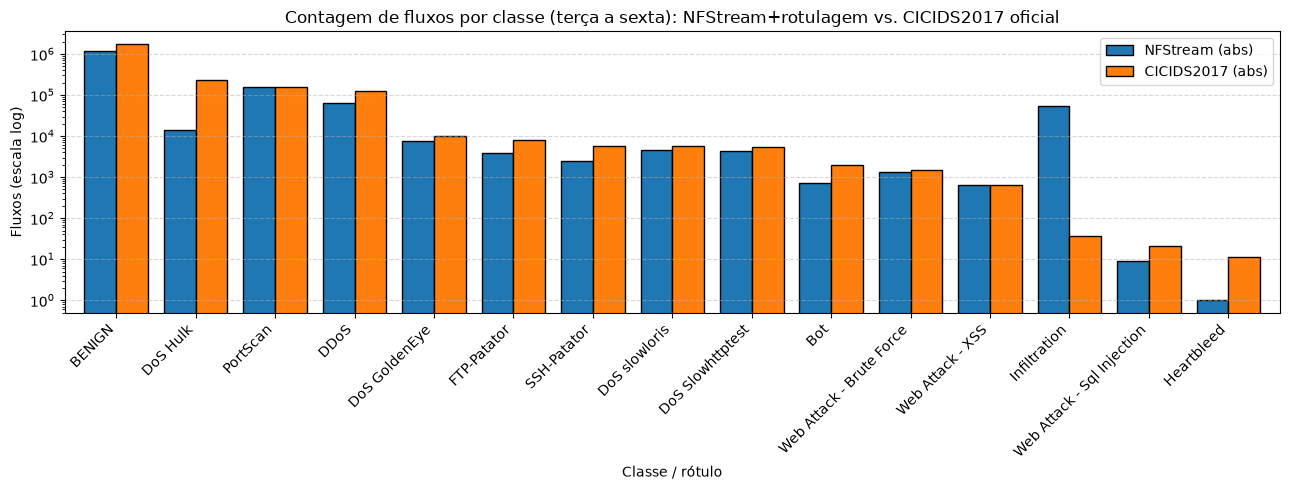

In [8]:
g = comparacao_total[["NFStream (abs)", "CICIDS2017 (abs)"]].copy()
g = g.replace(0, float("nan"))
ax = g.plot(kind="bar", figsize=(13, 5), logy=True, edgecolor="black", width=0.8)
ax.set_title("Contagem de fluxos por classe (terça a sexta): NFStream+rotulagem vs. CICIDS2017 oficial")
ax.set_xlabel("Classe / rótulo")
ax.set_ylabel("Fluxos (escala log)")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("comparacao_semana.png", dpi=150)
plt.show()

## 8. Conferência com a referência agregada (terça a sexta)

Tenho uma tabela de referência com a contagem por classe da base "CIC agregado" (terça a sexta). O total dela (1.489.872) é idêntico ao total de fluxos que obtive com o NFStream nos mesmos quatro dias, o que indica que foi construída sobre os mesmos fluxos, mudando só a rotulagem. A tabela abaixo mostra a razão entre a referência e o CSV oficial cru. No DoS Hulk, por exemplo, ela (0,061) é quase igual à razão entre a minha contagem e o oficial (0,062).

In [9]:
REFERENCIA_CIC_AGREGADO = {
    "BENIGN": 1_387_023,
    "Bot": 741,                    # Botnet-ARES
    "DDoS": 62_768,                # DDoS-LOIT
    "DoS GoldenEye": 7_554,
    "DoS Hulk": 14_080,
    "DoS Slowhttptest": 4_217,
    "DoS slowloris": 4_511,
    "FTP-Patator": 3_972,
    "Heartbleed": 8,
    "Infiltration": 35,
    "PortScan": 383,
    "SSH-Patator": 2_535,
    "Web Attack - Brute Force": 1_354,
    "Web Attack - Sql Injection": 12,
    "Web Attack - XSS": 679,
}

ref = pd.Series(REFERENCIA_CIC_AGREGADO, name="Referencia")
nomes_ref = {normalizar_label(k): k for k in REFERENCIA_CIC_AGREGADO}
ref.index = ref.index.map(normalizar_label)
oficial_cru = base_oficial["Label_norm"].value_counts()

conf = pd.DataFrame({"Oficial cru (abs)": oficial_cru, "Referencia (abs)": ref}).fillna(0).astype(int)
conf["Referencia / oficial cru"] = (conf["Referencia (abs)"] / conf["Oficial cru (abs)"].replace(0, float("nan"))).round(3)
conf.index = conf.index.map(lambda n: nomes_exibicao.get(n, nomes_ref.get(n, n)))
conf.loc["TOTAL"] = [conf["Oficial cru (abs)"].sum(), conf["Referencia (abs)"].sum(),
                     round(conf["Referencia (abs)"].sum() / conf["Oficial cru (abs)"].sum(), 3)]
conf

,Oficial cru (abs),Referencia (abs),Referencia / oficial cru
BENIGN,1743179.0,1387023.0,0.796
Bot,1966.0,741.0,0.377
DDoS,128027.0,62768.0,0.490
DoS GoldenEye,10293.0,7554.0,0.734
DoS Hulk,231073.0,14080.0,0.061
DoS Slowhttptest,5499.0,4217.0,0.767
DoS slowloris,5796.0,4511.0,0.778
FTP-Patator,7938.0,3972.0,0.500
Heartbleed,11.0,8.0,0.727
Infiltration,36.0,35.0,0.972


## 9. Teste: a referência é o CSV oficial sem linhas duplicadas?

Removi as linhas com `inf`/`NaN` e depois as duplicadas dos CSVs oficiais. O resultado foi 2.300.825 → 2.298.395 → 2.018.473 linhas, muito acima do total da referência (1.489.872). Portanto a referência não é o CSV oficial sem duplicadas, e sim uma contagem sobre os fluxos extraídos com o NFStream.

In [10]:
RODAR_DIAGNOSTICO = True

if RODAR_DIAGNOSTICO:
    import numpy as np

    arquivos = []
    for dia in dias_disponiveis:
        prefixo = DIAS[dia][1].lower()
        arquivos += sorted(f for f in glob.glob(os.path.join(PASTA_ORIGINAIS, "*.csv"))
                           if os.path.basename(f).lower().startswith(prefixo))
    cru = ler_csv_original_cicids2017(arquivos)
    n0 = len(cru)
    cru = cru.replace([np.inf, -np.inf], np.nan).dropna()
    n1 = len(cru)
    limpo = cru.drop_duplicates()
    n2 = len(limpo)
    print(f"linhas: {n0:,} -> sem inf/NaN: {n1:,} -> sem duplicadas: {n2:,}")

    limpo_cont = limpo["Label"].map(normalizar_label).value_counts()
    diag = pd.DataFrame({"Oficial sem duplicadas (abs)": limpo_cont, "Referencia (abs)": ref}).fillna(0).astype(int)
    diag.index = diag.index.map(lambda n: nomes_exibicao.get(n, nomes_ref.get(n, n)))
    diag

[ler_csv_original_cicids2017] dados/Tuesday-WorkingHours.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Wednesday-workingHours.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Friday-WorkingHours-Morning.pcap_ISCX.csv: lido com encoding='utf-8'
linhas: 2,300,825 -> sem inf/NaN: 2,298,395 -> sem duplicadas: 2,018,473


## Reflexão

- **Volume de fluxos:** o NFStream gerou 1.489.872 fluxos de terça a sexta, contra 2.300.825 nos CSVs oficiais (64,8%). Por dia (NFStream / oficial): terça 308.349 / 445.909, quarta 337.293 / 692.703, quinta 343.134 / 458.968 e sexta 501.096 / 703.245. Em todos os dias o NFStream produz menos fluxos, o que é coerente com diferenças na forma como cada ferramenta fecha um fluxo (timeouts e tratamento de FIN/RST). Como a comparação é por contagem e não fluxo a fluxo, essa diferença de granularidade afeta todas as classes.

- **Classes muito próximas do oficial:** PortScan (160.133 contra 158.930, +0,8%), Web Attack - XSS (661 contra 652) e Web Attack - Brute Force (1.349 contra 1.507, 89,5%). O PortScan é o melhor teste da rotulagem por IP e horário, porque tem um par de IP bem definido e dura mais de uma hora; a concordância mostra que o fuso `America/Moncton` e a consideração do IP pós-NAT `172.16.0.1` estão corretos.

- **Classes em que o NFStream tem cerca de 40% a 80% dos fluxos do oficial:** FTP-Patator (3.948 contra 7.938), SSH-Patator (2.464 contra 5.897), DDoS (62.980 contra 128.027), Bot (735 contra 1.966), DoS GoldenEye, slowloris e Slowhttptest (entre 74% e 79%). Esse padrão é compatível com o CICFlowMeter quebrando uma mesma conexão em mais de um fluxo; Engelen et al. (2021) documentam esse tipo de artefato na construção de fluxos da CICIDS2017. É uma hipótese, que não testei diretamente.

- **Heartbleed:** 1 fluxo no NFStream contra 11 no oficial. O ataque é uma única conexão longa (janela de cerca de 20 minutos). O CICFlowMeter fecha fluxos por timeout de 120 s, o que daria da ordem de 10 fluxos, e o NFStream usa `active_timeout` de 1800 s por padrão. Isso é consistente com a diferença.

- **DoS Hulk:** é a maior diferença entre as classes de DoS (14.287 contra 231.073, 6%). Não consegui explicar só com os timeouts, porque as outras classes de DoS ficam em torno de 75%. Fica como ponto a investigar.

- **Infiltration:** 55.134 fluxos na minha rotulagem contra 36 no oficial. Provavelmente a maior parte vem do portscan interno de quinta (15:04 a 15:45), que usa o critério amplo de vítima `*_local` (qualquer cliente de `192.168.10.x` que não seja servidor de infraestrutura), enquanto o oficial rotula poucos pares de IP. Ainda não decompus o total por janela para confirmar.

- **Comparação com a referência agregada:** o total da referência (1.489.872) é igual ao meu, o que indica que foi calculada sobre os mesmos fluxos do NFStream. Em dez classes de ataque a minha contagem fica a menos de 4% da referência (por exemplo DDoS 62.980 contra 62.768, DoS Hulk 14.287 contra 14.080, Bot 735 contra 741), então a extração e a rotulagem dessas classes estão alinhadas. As diferenças relevantes estão em PortScan (160.133 contra 383), Infiltration (55.134 contra 35), que explicam quase toda a diferença no BENIGN, e Heartbleed (1 contra 8); o Sql Injection (9 contra 12) é uma diferença pequena em valor absoluto. Como a minha contagem de PortScan fica próxima da do CSV oficial, a de 383 parece restritiva demais; preciso confirmar qual regra de IP e horário foi usada na referência.

- **Limitações:** as janelas de horário publicadas pelo CIC são aproximadas (Engelen et al., 2021); o rótulo é atribuído só por IP e horário, sem olhar porta nem comportamento do fluxo; e os rótulos de Web Attack do CSV oficial vêm com o traço corrompido, então comparo por uma chave normalizada.

In [11]:
import pandas as pd, numpy as np
from rotulagem_cicids2017 import ATTACK_WINDOWS, INTERNAL_INFRA_IPS

w = next(x for x in ATTACK_WINDOWS if x["victim"] == {"*_local"})
cols = ["src_ip", "dst_ip", "dst_port", "protocol", "bidirectional_packets", "bidirectional_first_seen_ms"]
f = pd.read_csv("captura_nfstream_thursday.csv", usecols=cols)

ok = lambda ips: ips.str.startswith("192.168.10.") & ~ips.isin(INTERNAL_INFRA_IPS)
a = list(w["attacker"])[0]
t = f["bidirectional_first_seen_ms"].between(w["start_ms"], w["end_ms"])
m = t & (((f["src_ip"] == a) & ok(f["dst_ip"])) | ((f["dst_ip"] == a) & ok(f["src_ip"])))
x = f[m].copy()
x["outro_ip"] = np.where(x["src_ip"] == a, x["dst_ip"], x["src_ip"])

print("fluxos na janela *_local:", len(x))
print(x["outro_ip"].value_counts().head(10))
print("portas de destino distintas:", x["dst_port"].nunique())
print(x["dst_port"].value_counts().head(10))
print("fluxos com <=3 pacotes: %.1f%%" % ((x["bidirectional_packets"] <= 3).mean() * 100))
print(x["protocol"].value_counts())

fluxos na janela *_local: 55126
outro_ip
192.168.10.5     10113
192.168.10.14     8106
192.168.10.15     8105
192.168.10.25     6597
192.168.10.9      5693
192.168.10.12     4128
192.168.10.16     4128
192.168.10.17     4128
192.168.10.19     4128
Name: count, dtype: int64
portas de destino distintas: 1127
dst_port
135      274
139      253
445      213
1        123
1042     107
1026     105
1041     104
1037      98
54031     97
49846     96
Name: count, dtype: int64
fluxos com <=3 pacotes: 52.6%
protocol
6     54892
17      197
1        37
Name: count, dtype: int64
